In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [2]:
J = np.array([
    [-1,  1,  1,  1,  1,  1,  1, -1],
    [-1, -1, -1, -1, -1, -1,  1, -1],
    [-1, -1, -1, -1, -1, -1,  1, -1],
    [-1, -1, -1, -1, -1, -1,  1, -1],
    [-1, -1, -1, -1, -1, -1,  1, -1],
    [ 1, -1, -1, -1, -1, -1,  1, -1],
    [ 1, -1, -1, -1, -1, -1,  1, -1],
    [-1,  1,  1,  1,  1,  1, -1, -1]
])

H = np.array([
    [ 1, -1, -1, -1, -1, -1,  1, -1],
    [ 1, -1, -1, -1, -1, -1,  1, -1],
    [ 1, -1, -1, -1, -1, -1,  1, -1],
    [ 1,  1,  1,  1,  1,  1,  1, -1],
    [ 1, -1, -1, -1, -1, -1,  1, -1],
    [ 1, -1, -1, -1, -1, -1,  1, -1],
    [ 1, -1, -1, -1, -1, -1,  1, -1],
    [ 1, -1, -1, -1, -1, -1,  1, -1]
])

# P = número de patrones; N = número de píxeles.
patrones = np.array([J.flatten(), H.flatten()])
print("Dimensiones:", patrones.shape)

Dimensiones: (2, 64)


In [3]:
def energia(q, X, beta):
    activaciones = beta * (X @ q)
    # Cálculo estable de log(sum(exp(...))).
    maximo = np.max(activaciones)
    log_suma = maximo + np.log(np.sum(np.exp(activaciones - maximo)))
    return 0.5 * np.sum(q**2) - log_suma / beta

In [4]:
def actualizar(q, X, beta):
    activaciones = beta * (X @ q)
    activaciones -= np.max(activaciones)  # Estabilidad numérica.
    pesos = np.exp(activaciones)
    pesos /= np.sum(pesos)
    return pesos @ X

In [5]:
def recuperar(q_inicial, X, beta, tolerancia=1e-8, max_iter=1000):
    q = q_inicial.astype(float).copy()
    historial_energia = [energia(q, X, beta)]
    for iteracion in range(max_iter):
        q_nuevo = actualizar(q, X, beta)
        historial_energia.append(energia(q_nuevo, X, beta))
        cambio = np.linalg.norm(q_nuevo - q)
        q = q_nuevo
        if cambio < tolerancia:
            break
    return q, historial_energia, iteracion + 1

def perturbar(patron, porcentaje):
    q = patron.flatten().copy()
    cantidad = int(round(porcentaje / 100 * len(q)))
    indices = np.random.choice(len(q), cantidad, replace=False)
    q[indices] *= -1
    return q

def porcentaje_acierto(estado, patron):
    binario = np.where(estado >= 0, 1, -1)
    return 100 * np.mean(binario == patron.flatten())

In [6]:
patron_original = J
porcentaje_perturbacion = 20
beta = 1.0

estado_inicial = perturbar(patron_original, porcentaje_perturbacion)
estado_final, historial, iteraciones = recuperar(estado_inicial, patrones, beta)
estado_final_binario = np.where(estado_final >= 0, 1, -1).reshape(8, 8)

print(f"Iteraciones: {iteraciones}")
print(f"Energía inicial: {historial[0]:.6f}")
print(f"Energía final: {historial[-1]:.6f}")
print(f"Recuperación: {porcentaje_acierto(estado_final, patron_original):.2f}%")

Iteraciones: 3
Energía inicial: -6.000000
Energía final: -32.000000
Recuperación: 100.00%


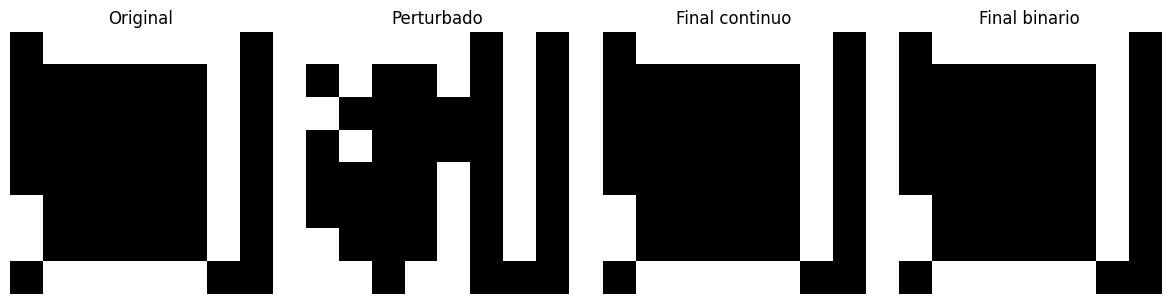

In [7]:
fig, ejes = plt.subplots(1, 4, figsize=(12, 3))
imagenes = [patron_original, estado_inicial.reshape(8, 8), estado_final.reshape(8, 8), estado_final_binario]
titulos = ["Original", "Perturbado", "Final continuo", "Final binario"]
for eje, imagen, titulo in zip(ejes, imagenes, titulos):
    eje.imshow(imagen, cmap="gray", vmin=-1, vmax=1)
    eje.set_title(titulo)
    eje.axis("off")
plt.tight_layout()
plt.show()

In [8]:
estado_inicial_beta = perturbar(J, 20)
valores_beta = [0.1, 0.5, 1, 2, 5, 10]
resultados_beta = {}

for beta in valores_beta:
    final, historial_beta, iteraciones_beta = recuperar(estado_inicial_beta, patrones, beta)
    resultados_beta[beta] = (final, historial_beta, iteraciones_beta)
    print(f"beta={beta:>4}: iteraciones={iteraciones_beta:>4}, energía final={historial_beta[-1]:.6f}, recuperación={porcentaje_acierto(final, J):.2f}%")

beta= 0.1: iteraciones=  11, energía final=-32.129295, recuperación=100.00%
beta= 0.5: iteraciones=   3, energía final=-32.000000, recuperación=100.00%
beta=   1: iteraciones=   2, energía final=-32.000000, recuperación=100.00%
beta=   2: iteraciones=   2, energía final=-32.000000, recuperación=100.00%
beta=   5: iteraciones=   2, energía final=-32.000000, recuperación=100.00%
beta=  10: iteraciones=   2, energía final=-32.000000, recuperación=100.00%


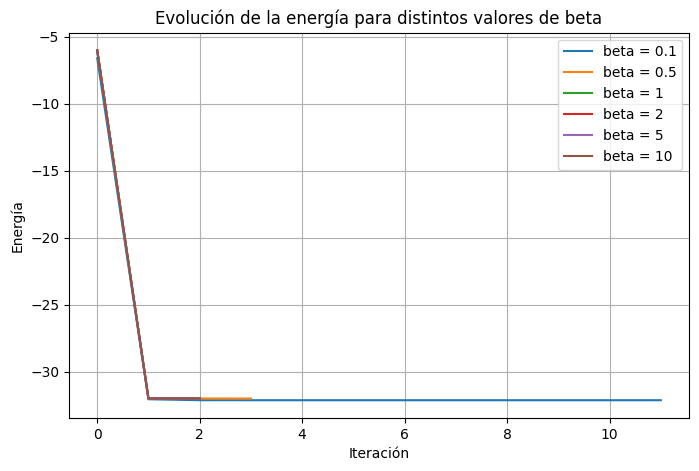

In [9]:
plt.figure(figsize=(8, 5))
for beta, (_, historial_beta, _) in resultados_beta.items():
    plt.plot(historial_beta, label=f"beta = {beta}")
plt.xlabel("Iteración")
plt.ylabel("Energía")
plt.title("Evolución de la energía para distintos valores de beta")
plt.legend()
plt.grid(True)
plt.show()

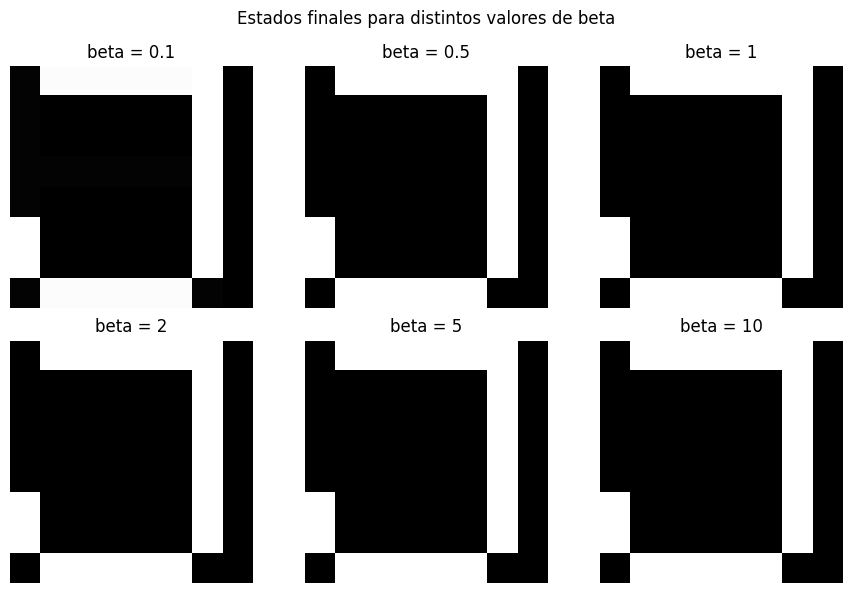

In [10]:
fig, ejes = plt.subplots(2, 3, figsize=(9, 6))
for eje, beta in zip(ejes.flat, valores_beta):
    final = resultados_beta[beta][0]
    eje.imshow(final.reshape(8, 8), cmap="gray", vmin=-1, vmax=1)
    eje.set_title(f"beta = {beta}")
    eje.axis("off")
plt.suptitle("Estados finales para distintos valores de beta")
plt.tight_layout()
plt.show()